--------------------------------
Mức nhiễu: 0.5
Intercept: 4.007268627217773
Slope: 3.0261758951069613
MSE: 0.2711559656363676
R2 Score: 0.9086739328032202


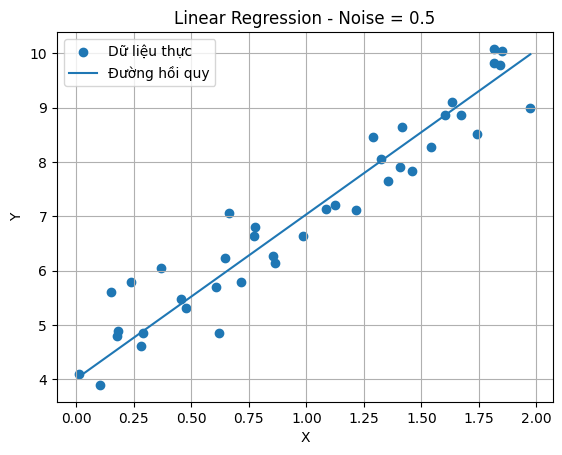

--------------------------------
Mức nhiễu: 2
Intercept: 3.5605276708569193
Slope: 3.254487365923858
MSE: 4.422337103550001
R2 Score: 0.3575793083601341


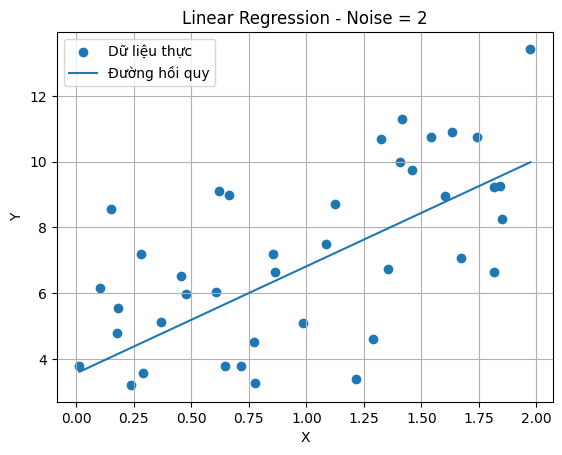

--------------------------------
Mức nhiễu: 5
Intercept: 4.50346588018844
Slope: 2.4426905073700946
MSE: 26.045503582167203
R2 Score: 0.2291294203245534


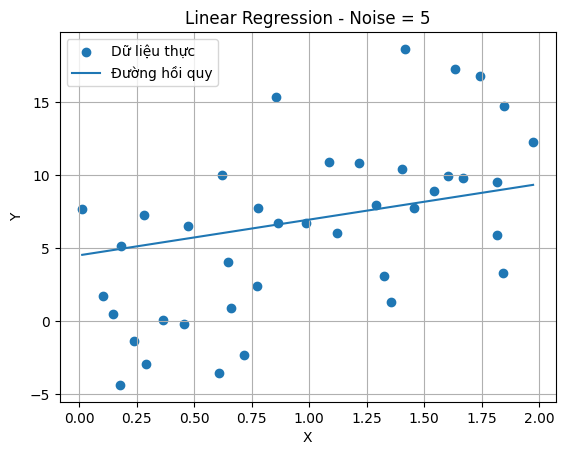

In [1]:
# BTVN1: Thay đổi độ nhiễu và kiểm tra độ chính xác của mô hình
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Giữ kết quả ngẫu nhiên giống nhau mỗi lần chạy
np.random.seed(42)

# Tạo dữ liệu X
X = 2 * np.random.rand(200, 1)

# Hàm thực tế: y = 4 + 3X
# Thử 3 mức nhiễu khác nhau
noise_levels = [0.5, 2, 5]

for noise_level in noise_levels:
    # Tạo nhiễu
    noise = noise_level * np.random.randn(200, 1)
    # Tạo y
    y = 4 + 3 * X + noise
    # Chia dữ liệu 80% train - 20% test
    X_train, X_test, y_train, y_test = train_test_split(X, y,
        test_size=0.2, random_state=42)

    # Tạo mô hình
    model = LinearRegression()
    # Huấn luyện
    model.fit(X_train, y_train)
    # Dự đoán
    y_pred = model.predict(X_test)

    # Đánh giá
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("--------------------------------")
    print("Mức nhiễu:", noise_level)
    print("Intercept:", model.intercept_[0])
    print("Slope:", model.coef_[0][0])
    print("MSE:", mse)
    print("R2 Score:", r2)

    # Vẽ biểu đồ
    plt.figure()
    plt.scatter(X_test, y_test, label="Dữ liệu thực")

    # Sắp xếp để đường hồi quy không bị gãy
    index = np.argsort(X_test[:, 0])
    plt.plot(X_test[index], y_pred[index], label="Đường hồi quy")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Linear Regression - Noise = {noise_level}")
    plt.legend()
    plt.grid()
    plt.show()